# ViZDoom Basic: DQN with AgileRL

[![Video about this notebook's results](artifacts/plots_and_figures/video_thumbnail.jpg)](https://www.youtube.com/watch?v=cK0BED0Sp-Y)

In this notebook, we're going to train a vanilla DQN agent to beat the Basic scenario in ViZDoom, using only visual observations from the game!

This notebook won't be going over the specifics of DQN or RL as a whole, more just how to use AgileRL for a quick DQN test on VizDoom.

We'll be using the AgileRL library for our DQN implementation. AgileRL is built for population-based training, but a single agent works just as well, and it's easy to pick up and extend. It ships with DQN, Rainbow, and PPO ect, and in my experience it converges faster than Stable Baselines3 in experiments like this one. That makes it a perfect for quick tests!

Basic is as simple as Doom gets: one room, one pistol, and one Cacodemon, with the goal of having Doomguy kill it! It's a good first test for learning straight from pixels. The official writeup of the scenario is [here](https://vizdoom.farama.org/environments/default/#basic).

One twist: training uses the stock scenario, but evaluation and recording use `basic_outro`, a version I made so the episode doesn't end the instant the demon dies. This lets the death animation make it into the video instead of cutting straight to black. This is optional however, and the notebook should be robust enough so that it doesn't crash if it can't find it.

Similarly it also tries to use the original Doom WADs if it can find them.

The notebook was designed to run in place in the repo, however it also supports running on Google Colab, with the option of using Google Drive to save artifacts. 

If you're interested I also made a video about the agent trained with this notebook which you can checkout [here](https://www.youtube.com/watch?v=cK0BED0Sp-Y). The video shows a 500k step run, but this notebook only uses about 50k which is more than enough. 


# Setup
First, we'll install the dependencies and load the imports.


Install the pinned dependencies first.

In [1]:
import sys

# Update the required system packages when running on Colab.
if "google.colab" in sys.modules:
    !apt-get update -qq
    !apt-get install -y -qq libopenal1 libopenal-dev > /dev/null

# Install the Python packages used throughout the notebook.
%pip install -q vizdoom==1.3.1 agilerl==2.8.4 gymnasium==1.3.0 imageio==2.38.0 imageio-ffmpeg==0.6.0 opencv-python==5.0.0.93 scipy==1.17.1 numpy==2.4.6 pandas==3.0.5 torch==2.13.0 matplotlib==3.11.1

Note: you may need to restart the kernel to use updated packages.


# Imports
Next, import everything used throughout the notebook.


In [2]:
import json
import os
import shutil
import subprocess
import sys
from datetime import datetime
from pathlib import Path

import gymnasium
import imageio.v2 as imageio
import imageio_ffmpeg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch


from agilerl.algorithms.dqn import DQN
from agilerl.components.replay_buffer import ReplayBuffer
from agilerl.training.train_off_policy import train_off_policy
from gymnasium.spaces import Box
from gymnasium.wrappers import FrameStackObservation, ResizeObservation, TransformObservation, TransformReward
from IPython.display import Image, display
from scipy.io import wavfile


import vizdoom as vzd
from vizdoom import gymnasium_wrapper  # registers the Vizdoom* gymnasium envs
from vizdoom.gymnasium_wrapper.base_gymnasium_env import VizdoomEnv

/opt/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Experiment Setup
The experiment uses a standard DQN on pixels setup. The agent acts every 4 frames and sees the last 4 frames stacked at 84x84, which gives it a sense of motion. Basic has 3 buttons, and we allow only one at a time, so the available actions are move left, move right, shoot, and do nothing.

`EVAL_EPISODES` controls how many episodes we use to score each checkpoint. `RECORD_EPISODES` controls how many videos we save. Set `RECORD_CHECKPOINTS` to `"all"` if you want every generation, although converting all of them takes a while.


In [3]:
ENV_NAME = "VizdoomBasic-v1"
NUM_ENVS = 2
FRAME_SKIP = 4          # act every 4 frames
STACK_SIZE = 4          # last 4 frames, so the agent can see motion
OBS_SIZE = (84, 84)
MAX_BUTTONS_PRESSED = 1 # one button at a time

EVAL_EPISODES = 5
RECORD_EPISODES = 3
RECORD_CHECKPOINTS = "best"  # or "all"


All the path logic lives in the next few cells, so the rest of the notebook doesn't need to care whether it's running on Colab or locally.


On Colab, `USE_DRIVE` keeps the run in Google Drive so it survives the session. Otherwise, everything stays in the notebook's folder.


In [4]:
USE_DRIVE = True # Colab only: keep the experiment (and every output) in Google Drive
EXPERIMENT = "basic-dqn-AgileRL"

if "google.colab" in sys.modules and USE_DRIVE:
    from google.colab import drive

    drive.mount("/content/drive")
    experiment_dir = Path("/content/drive/MyDrive/rl-epsilon/vizdoom-agilerl-experiments") / EXPERIMENT
elif "google.colab" in sys.modules:
    experiment_dir = Path("/content") / EXPERIMENT  # lost when the Colab session ends
else:
    experiment_dir = Path.cwd()  # local: the notebook's own folder
print("experiment:", experiment_dir)

experiment: /Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/basic-dqn-AgileRL


ViZDoom ships with Freedoom. But if `DOOM2.WAD` is in the `WADS` folder, we use that instead. Always better to use the original assets in my opinion! The scenario follows the same fallback pattern: `basic_outro` lets the death animation play, but if that file isn't available, we use the stock scenario.


In [5]:
USE_DOOM2_WAD = True  # use DOOM2.WAD if found, otherwise ViZDoom's bundled Freedoom
SCENARIO = "basic_outro.cfg"   # custom scenario in scenario_files/
STOCK_SCENARIO = "basic.cfg"  # bundled with ViZDoom, used if the custom one is missing

custom_cfg = experiment_dir / "scenario_files" / SCENARIO
scenario_cfg = str(custom_cfg if custom_cfg.is_file() else Path(vzd.scenarios_path) / STOCK_SCENARIO)
SCENARIO_NAME = Path(scenario_cfg).stem

wad = experiment_dir.parent / "WADS" / "DOOM2.WAD"
DOOM_WAD = str(wad) if USE_DOOM2_WAD and wad.is_file() else None
IWAD_NAME = Path(DOOM_WAD).name if DOOM_WAD else "freedoom2"
print("scenario:", scenario_cfg)
print("IWAD:", IWAD_NAME)

scenario: /Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/basic-dqn-AgileRL/scenario_files/basic_outro.cfg
IWAD: DOOM2.WAD


Each run gets its own timestamped folder. The best model, charts, and videos are copied to `artifacts`.


In [6]:
run_dir = experiment_dir / "training-runs" / f"run-{datetime.now():%Y%m%d_%H%M%S}"
checkpoint_dir = run_dir / "checkpoints"
recording_dir = run_dir / "recordings"
artifacts_dir = experiment_dir / "artifacts"
model_dir = artifacts_dir / "model"
video_dir = artifacts_dir / "video"
figure_dir = artifacts_dir / "plots_and_figures"
for d in (checkpoint_dir, recording_dir, model_dir, video_dir, figure_dir):
    d.mkdir(parents=True, exist_ok=True)

checkpoint_path = checkpoint_dir / "DQN.pt"
best_model_path = model_dir / "best_model.pt"
metrics_csv = figure_dir / "generation_metrics.csv"
results_path = artifacts_dir / "results.json"
print("run:", run_dir.name)


run: run-20261020_162808


# Environment

Next, we'll build the environment used to train Doomguy.

Basic takes place in one room. Doomguy has a pistol and can move left, move right, or fire. A Cacodemon spawns somewhere along the far wall. A kill is worth +106, every tic alive costs 1, and a missed shot costs 5, so the agent has to line up its shots instead of wasting ammunition.

`make_env` turns each frame into an 84x84 grayscale image and stacks the last 4 frames so the network can see motion. Rewards are divided by 100, which makes a kill worth 1.06 instead of 106.

Training uses the stock scenario. For evaluation and recording, we pass in our custom version of the same level so the death animation has time to play. We then create `NUM_ENVS` copies to collect experience a little faster.


In [7]:
def make_env(config_file=None):
    """Stock scenario for training. Pass a config file for eval and recording."""
    kwargs = dict(
        render_mode="rgb_array",
        frame_skip=FRAME_SKIP,
        screen_resolution=vzd.ScreenResolution.RES_200X125,
        max_buttons_pressed=MAX_BUTTONS_PRESSED,
        treat_episode_timeout_as_truncation=False,
    )
    if DOOM_WAD:
        kwargs["doom_game_path"] = DOOM_WAD
    env = VizdoomEnv(config_file=config_file, **kwargs) if config_file else gymnasium.make(ENV_NAME, **kwargs)

    h, w, _ = env.observation_space["screen"].shape
    env = TransformObservation(
        env,
        lambda obs: (obs["screen"] @ np.array([0.299, 0.587, 0.114])).astype(np.uint8),
        Box(low=0, high=255, shape=(h, w), dtype=np.uint8),
    )  # grayscale
    env = ResizeObservation(env, OBS_SIZE)  # 84x84
    env = FrameStackObservation(env, stack_size=STACK_SIZE)  # last 4 frames
    return TransformReward(env, lambda r: r / 100.0)  # A kill is ~1.06 instead of 106.

# Create the vectorized training environment.
env = gymnasium.vector.SyncVectorEnv(
    [make_env] * NUM_ENVS, autoreset_mode=gymnasium.vector.AutoresetMode.SAME_STEP
)

objc[20798]: Class SDLApplication is implemented in both /opt/miniconda3/lib/python3.13/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x15ccd0a68) and /opt/miniconda3/lib/python3.13/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x16b03c890). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[20798]: Class SDLAppDelegate is implemented in both /opt/miniconda3/lib/python3.13/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x15ccd0ab8) and /opt/miniconda3/lib/python3.13/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x16b03c8e0). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[20798]: Class SDLTranslatorResponder is implemented in both /opt/miniconda3/lib/python3.13/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x15ccd0b30) and /opt/miniconda3/lib/python3.13/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x16b03c958). This may cause spurio

# Agent
Now we'll build the DQN that will learn to play. The network uses 3 convolution networks to process the image input, and then a fully connected layer for additional processing. this should be more than enough room in the network to train our agent.


In [8]:
net_config = {
    "encoder_config": {"channel_size": [32, 64, 64], "kernel_size": [8, 4, 3], "stride_size": [4, 2, 1]},  # 3 conv layers
    "head_config": {"hidden_size": [256], "max_mlp_nodes": 1024},  # smaller than the original Atari head
}


The replay buffer holds past transitions so the agent can learn from more than just its most recent step. Training runs for 50,000 steps, with each 2,000-step block treated as a generation. AgileRL evaluates the agent and saves a checkpoint after each generation, giving us 25 checkpoints to compare. Learning begins after the buffer contains 1,000 transitions.


In [9]:
device = "cuda" if torch.cuda.is_available() else "cpu"
INIT_HP = {
    "BATCH_SIZE": 64,
    "LR": 1e-4,
    "GAMMA": 0.99,             # how much future reward counts
    "MEMORY_SIZE": 100_000,    # replay buffer; oldest transitions get dropped
    "LEARN_STEP": 4,           # one update every 4 steps, across all envs
    "TAU": 0.001,              # how fast the target network follows the main one
    "LEARNING_DELAY": 1000,    # fill the buffer a bit before learning starts
    "MAX_STEPS": 50_000,
    "EVO_STEPS": 2_000,        # steps per generation
    "EVAL_LOOP": 3,            # episodes AgileRL plays at the end of a generation
    "CHECKPOINT": 2_000,       # one checkpoint per generation, 25 total
}

memory = ReplayBuffer(max_size=INIT_HP["MEMORY_SIZE"], device=device)
dqn_agent = DQN(
    observation_space=env.single_observation_space,
    action_space=env.single_action_space,
    net_config=net_config,
    batch_size=INIT_HP["BATCH_SIZE"],
    lr=INIT_HP["LR"],
    learn_step=INIT_HP["LEARN_STEP"],
    gamma=INIT_HP["GAMMA"],
    tau=INIT_HP["TAU"],
    device=device,
)


We'll use a small hack to gather our own metrics during training. By wrapping the agent's test function, we can preserve values that AgileRL would otherwise clear. In this case, we record the mean loss and evaluation fitness for each generation.


In [10]:
history = []
_test = DQN.test.__get__(dqn_agent)


def test_and_log(*args, **kwargs):
    m = dqn_agent.metrics
    row = {"steps": m.steps, "loss": m.get_mean("loss")}  # read before train_off_policy clears it
    row["eval_fitness"] = _test(*args, **kwargs)
    history.append(row)
    return row["eval_fitness"]


dqn_agent.test = test_and_log


# Training
The agent starts with fully random actions and gradually decays epsilon to 5%. On my Mac, a 50k-step run usually takes around 15–25 minutes depending on how many other processes I have running. 


In [11]:
train_off_policy(
    env=env,
    env_name=ENV_NAME,
    algo="DQN",
    pop=[dqn_agent],
    memory=memory,
    init_hp=INIT_HP,
    max_steps=INIT_HP["MAX_STEPS"],
    evo_steps=INIT_HP["EVO_STEPS"],
    eval_loop=INIT_HP["EVAL_LOOP"],
    learning_delay=INIT_HP["LEARNING_DELAY"],
    checkpoint=INIT_HP["CHECKPOINT"],
    checkpoint_path=str(checkpoint_path),
    eps_start=1.0,
    eps_end=0.05,
    eps_decay=0.9995,
    verbose=False,  # the per-generation table breaks up the progress bar in notebooks
)
env.close()

Training Progress │ 100% │ ████████████████████ │ 50000/50000 steps │ ⏱️ 31:21 │ ⏳ 00:00 │ 26.58step/s


# Evaluation
During training AgileRL does do an evaluation step where it saves a checkpoint of the model and runs a few episodes to score teh generation and keeps track of the best model, but I decided to go ahead and include a full evaluation loop on all generations by reloading each checkpoint. This makes it easier to use custom eval environments for recording later, such as our custom scenario allowing for the end animation to play out. 


`load_agent` loads a checkpoint, while `play` runs one episode and returns its total reward and action history.


In [12]:
def load_agent(path):
    agent = DQN.load(str(path), device=device)
    agent.set_training_mode(False)
    return agent


def play(env, agent, obs):
    """Run one greedy episode from `obs`; returns (total_reward, actions)."""
    total, actions, done = 0.0, [], False
    while not done:
        action = int(agent.get_action(obs[None])[0])
        obs, reward, terminated, truncated, _ = env.step(action)
        total += reward
        actions.append(action)
        done = terminated or truncated
    return total, actions

AgileRL puts the step count at the end of each filename, so sorting by that value places the checkpoints in generation order.


In [13]:
checkpoints = sorted(checkpoint_dir.glob("*.pt"), key=lambda p: int(p.stem.split("_")[-1]))
print(f"found {len(checkpoints)} checkpoints")

found 25 checkpoints


We play `EVAL_EPISODES` episodes with each checkpoint and record the rewards. The checkpoint with the highest average wins; ties go to the later generation. The selected checkpoint is then copied to `artifacts`.


In [14]:
eval_env = make_env(scenario_cfg)
eval_rewards = []
best_gen = 0
for gen, ckpt in enumerate(checkpoints):
    agent = load_agent(ckpt)
    rewards = []
    for episode in range(EVAL_EPISODES):
        obs, _ = eval_env.reset()
        reward, _ = play(eval_env, agent, obs)
        rewards.append(reward)
    eval_rewards.append(rewards)
    mean = np.mean(rewards)
    print(f"gen {gen:>2}  mean={mean:6.2f}  rewards={np.round(rewards, 2).tolist()}")
    if mean >= np.mean(eval_rewards[best_gen]):  # ties go to the later generation
        best_gen = gen
eval_env.close()

best_checkpoint = checkpoints[best_gen]
shutil.copy2(best_checkpoint, best_model_path)
print(f"best: gen {best_gen} ({best_checkpoint.name}), mean eval reward {np.mean(eval_rewards[best_gen]):.2f}")


gen  0  mean= -3.50  rewards=[-3.5, -3.5, -3.5, -3.5, -3.5]
gen  1  mean= -3.22  rewards=[-2.4, -3.5, -3.5, -3.21, -3.5]
gen  2  mean= -2.75  rewards=[-3.5, -3.5, -3.5, -3.5, 0.26]
gen  3  mean= -0.84  rewards=[-3.75, -0.37, -0.37, -0.03, 0.3]
gen  4  mean= -2.20  rewards=[-3.85, 0.35, -0.13, -3.75, -3.6]
gen  5  mean= -2.38  rewards=[-3.9, -3.75, -0.19, 0.07, -4.15]
gen  6  mean= -0.06  rewards=[0.18, -0.37, 0.3, -0.49, 0.08]
gen  7  mean=  0.12  rewards=[0.06, -0.21, 0.23, 0.23, 0.3]
gen  8  mean= -0.78  rewards=[0.28, -3.5, -0.25, 0.2, -0.65]
gen  9  mean= -0.68  rewards=[0.19, 0.35, -0.57, 0.4, -3.75]
gen 10  mean= -0.57  rewards=[0.03, 0.16, -3.55, 0.27, 0.25]
gen 11  mean= -0.68  rewards=[-0.21, 0.12, -3.55, 0.28, -0.04]
gen 12  mean=  0.14  rewards=[0.17, -0.09, 0.19, 0.24, 0.17]
gen 13  mean= -0.83  rewards=[-0.06, -0.18, 0.23, 0.19, -4.35]
gen 14  mean= -0.19  rewards=[-1.7, 0.12, 0.35, 0.19, 0.11]
gen 15  mean=  0.19  rewards=[0.31, 0.07, 0.1, 0.23, 0.25]
gen 16  mean= -0.61 

# Analysis
Let's see how it did! Training is noisy and the eval episodes aren't seeded, so your curves won't match these exactly. The notes below are about the general shape.


## Metrics
One row per generation: the training loss, AgileRL's evaluation fitness, and our checkpoint evaluation's mean and standard deviation. The full table gets saved as a CSV in `artifacts`. Here we just show the first few generations, the best one, and the last few.


In [15]:
metrics = pd.DataFrame(history)
metrics.index.name = "generation"
metrics["ckpt_eval_mean"] = [np.mean(r) for r in eval_rewards]
metrics["ckpt_eval_std"] = [np.std(r) for r in eval_rewards]
shown = pd.concat([metrics.head(3), metrics.loc[[best_gen]], metrics.tail(3)])
shown[~shown.index.duplicated()]

,steps,loss,eval_fitness,ckpt_eval_mean,ckpt_eval_std
generation,,,,,
0,2000,0.013786,-3.000000,-3.500,0.000000
1,4000,0.007076,-2.341667,-3.222,0.426070
2,6000,0.004005,-1.038333,-2.748,1.504000
15,32000,0.008853,0.690000,0.192,0.091739
22,46000,0.006698,-0.570000,0.034,0.118929
23,48000,0.006916,0.701667,-0.032,0.114088
24,50000,0.006766,0.620000,-0.110,0.108259


In [16]:
metrics.to_csv(metrics_csv)


## Charts
Saved to `artifacts/plots_and_figures`, and shown here too.


In [17]:
def save(fig, name):
    fig.savefig(figure_dir / name, dpi=150, bbox_inches="tight")
    plt.show()


gens = metrics.index

**Loss.** The loss drops quickly, rises again once the agent starts landing kills, and then settles. That bump is normal: early rewards are small and easy to predict, while kills produce larger, less predictable targets. This chart doesn't tell us how well our agent performed, but rather how much pressure there was on the agent to modify it's behavior. So that bump meant that the agent was finding high rewards and the process was heavily influencing the network to change to get more of those rewards. 


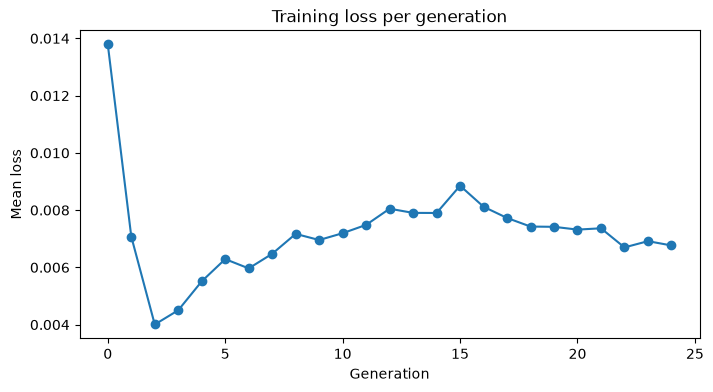

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(gens, metrics["loss"], marker="o")
ax.set(xlabel="Generation", ylabel="Mean loss", title="Training loss per generation")
save(fig, "loss.png")

**Average reward.** Both lines should climb and then level off once the agent kills the demon reliably. Blue shows AgileRL's evaluation during training. Orange shows our evaluation on the outro scenario, with the shaded band representing one standard deviation.

The band is wide early in training because a kill produces a small positive return while a timeout produces a large negative one, so a single timeout can drag down the average. Orange sits below blue because the outro continues for about 50 tics after the kill, and every tic carries a small penalty, naturally meaning our eval episodes will have a lower final reward. 


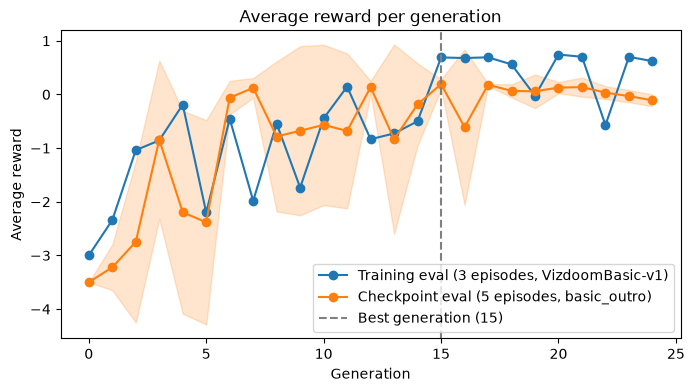

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(gens, metrics["eval_fitness"], marker="o", label=f"Training eval ({INIT_HP['EVAL_LOOP']} episodes, {ENV_NAME})")
(line,) = ax.plot(gens, metrics["ckpt_eval_mean"], marker="o", label=f"Checkpoint eval ({EVAL_EPISODES} episodes, {SCENARIO_NAME})")
ax.fill_between(gens, metrics["ckpt_eval_mean"] - metrics["ckpt_eval_std"],
                metrics["ckpt_eval_mean"] + metrics["ckpt_eval_std"], color=line.get_color(), alpha=0.2)
ax.axvline(best_gen, color="gray", linestyle="--", label=f"Best generation ({best_gen})")
ax.set(xlabel="Generation", ylabel="Average reward", title="Average reward per generation")
ax.legend()
save(fig, "average_reward.png")

# Recording
To record the trained agent, we save ViZDoom's `.lmp` demos—which store only the inputs—and then replay them at 720p.


The Gymnasium wrapper doesn't expose demo recording, so `reset_with_lmp` temporarily replaces the reset function with one that starts a recording. `flush_lmp` begins the next episode so the file is actually written.

One gotcha: ViZDoom hangs if the demo path is longer than about 112 characters. We pass a path relative to the working directory, which keeps it short locally. Paths are longer on Colab when using Drive, so recording the best model still works, but `RECORD_CHECKPOINTS = "all"` can hang. Set `USE_DRIVE = False` if you want a video of every generation on Colab.


In [20]:
def reset_with_lmp(env, lmp_path):
    base = env.unwrapped
    orig_reset = base.reset

    def recorded_reset(*, seed=None, options=None):
        gymnasium.Env.reset(base, seed=seed)
        game_seed = int(
            base.np_random.integers(0, np.iinfo(np.uint32).max + 1, dtype=np.uint32)
        )
        base.game.set_seed(game_seed)
        if not base.game.is_running():
            base.game.init()
        # ViZDoom hangs if the demo path is longer than ~112 characters, so pass it relative to the working directory
        base.game.new_episode(os.path.relpath(lmp_path))
        base.state = base.game.get_state()
        return base._VizdoomEnv__collect_observations(), {}

    base.reset = recorded_reset
    try:
        return env.reset()
    finally:
        base.reset = orig_reset


def flush_lmp(env):
    env.unwrapped.game.new_episode()

We record `RECORD_EPISODES` episodes with the best checkpoint, or with every checkpoint when `RECORD_CHECKPOINTS` is set to `"all"`. Best-model videos go in `artifacts/video`; all others remain in the run folder. Existing best-model videos are cleared first so they don't get mixed with the current run.


In [21]:
assert RECORD_CHECKPOINTS in ("best", "all")
record_checkpoints = [best_checkpoint] if RECORD_CHECKPOINTS == "best" else checkpoints

for old in video_dir.glob("best_episode_*"):
    old.unlink()

In [22]:
record_env = make_env(scenario_cfg)
lmps = []
lmp_rewards = {}
for ckpt in record_checkpoints:
    gen = checkpoints.index(ckpt)
    out_dir, prefix = (video_dir, "best") if ckpt == best_checkpoint else (recording_dir, f"gen_{gen}")
    agent = load_agent(ckpt)
    for episode in range(RECORD_EPISODES):
        lmp = out_dir / f"{prefix}_episode_{episode}.lmp"
        obs, _ = reset_with_lmp(record_env, lmp)
        reward, _ = play(record_env, agent, obs)
        print(f"gen {gen:>2}  episode {episode}  reward={reward:.2f}  -> {lmp.name}")
        lmps.append(lmp)
        lmp_rewards[lmp] = reward
flush_lmp(record_env)
record_env.close()

gen 15  episode 0  reward=0.20  -> best_episode_0.lmp
gen 15  episode 1  reward=0.28  -> best_episode_1.lmp
gen 15  episode 2  reward=0.28  -> best_episode_2.lmp


`lmp_to_mp4` replays each demo at 720p with the HUD enabled. The result looks much better than the 84x84 input used for training because we're replaying the actions in a fresh game rather than saving what the network saw. CRF 18, tuned for Doom's flat textures, keeps the files small enough for GitHub. Audio capture is silent on my Mac, so locally generated videos have no sound. Encoding takes a while because the encoder is configured to prioritize compression quality over speed.


In [23]:
SAMPLE_RATE = 22050
VIDEO_PARAMS = dict(  # x264 at constant quality: CRF 18 is visually lossless, and "animation" suits Doom's flat textures
    fps=35, codec="libx264", quality=None, macro_block_size=8,
    ffmpeg_params=["-crf", "18", "-preset", "veryslow", "-tune", "animation", "-movflags", "+faststart"],
)


def lmp_to_mp4(lmp_path):
    """Replay an .lmp at 720p with HUD and audio, and write it next to the .lmp as .mp4."""
    lmp_path = Path(lmp_path)
    mp4_path = lmp_path.with_suffix(".mp4")
    silent_path = lmp_path.with_name(lmp_path.stem + "_silent.mp4")
    wav_path = lmp_path.with_suffix(".wav")

    game = vzd.DoomGame()
    game.load_config(scenario_cfg)
    if DOOM_WAD:
        game.set_doom_game_path(DOOM_WAD)
    game.set_screen_resolution(vzd.ScreenResolution.RES_1280X720)
    game.set_render_hud(True)
    game.set_render_corpses(True)
    game.set_window_visible(False)
    game.set_audio_buffer_enabled(True)
    game.set_audio_sampling_rate(vzd.SamplingRate.SR_22050)
    game.set_audio_buffer_size(1)
    game.add_game_args("+snd_efx 0")
    game.set_mode(vzd.Mode.SPECTATOR)
    game.init()

    frames, audio = [], []
    try:
        game.replay_episode(os.path.relpath(lmp_path))  # relative for the same path length limit as recording
        while not game.is_episode_finished():
            state = game.get_state()
            if state is not None:
                frames.append(np.transpose(state.screen_buffer, (1, 2, 0)))
                if state.audio_buffer is not None:
                    audio.append(state.audio_buffer)
            game.advance_action()
    finally:
        game.close()

    imageio.mimsave(silent_path, frames, **VIDEO_PARAMS)

    audio = np.concatenate(audio) if audio else np.zeros(1)
    if not audio.any():  # no sound captured (e.g. on macOS): keep the silent video
        silent_path.replace(mp4_path)
        return mp4_path

    wavfile.write(wav_path, SAMPLE_RATE, audio)
    subprocess.run(
        [imageio_ffmpeg.get_ffmpeg_exe(), "-y", "-i", silent_path, "-i", wav_path,
         "-c:v", "copy", "-c:a", "aac", "-shortest", mp4_path],
        check=True, capture_output=True,
    )
    silent_path.unlink()
    wav_path.unlink()
    return mp4_path

In [24]:
mp4s = [lmp_to_mp4(lmp) for lmp in lmps]
mp4s

[PosixPath('/Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/basic-dqn-AgileRL/artifacts/video/best_episode_0.mp4'),
 PosixPath('/Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/basic-dqn-AgileRL/artifacts/video/best_episode_1.mp4'),
 PosixPath('/Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/basic-dqn-AgileRL/artifacts/video/best_episode_2.mp4')]

For a quick preview, the highest-scoring episode is converted to a deliberately small GIF that plays directly in the notebook and on GitHub. The full-resolution MP4s remain in `artifacts/video`.


best_episode_1.gif  reward=0.28  (0.4 MB)


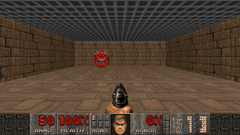

In [25]:
GIF_WIDTH = 240
GIF_FPS = 10


def mp4_to_gif(mp4_path):
    """Write a small GIF next to an MP4, with a palette built from the video so the colors hold up."""
    gif_path = Path(mp4_path).with_suffix(".gif")
    vf = (
        f"fps={GIF_FPS},scale={GIF_WIDTH}:-1:flags=lanczos,split[a][b];"
        "[a]palettegen=max_colors=128:stats_mode=diff[p];[b][p]paletteuse=dither=bayer:bayer_scale=5:diff_mode=rectangle"
    )
    subprocess.run([imageio_ffmpeg.get_ffmpeg_exe(), "-y", "-i", mp4_path, "-vf", vf, gif_path], check=True, capture_output=True)
    return gif_path


best_mp4 = max(
    (m for m in mp4s if m.name.startswith("best")),
    key=lambda m: lmp_rewards[m.with_suffix(".lmp")],
)
best_gif = mp4_to_gif(best_mp4)
print(f"{best_gif.name}  reward={lmp_rewards[best_mp4.with_suffix('.lmp')]:.2f}  ({best_gif.stat().st_size / 2**20:.1f} MB)")
display(Image(filename=str(best_gif)))

# Results
A short summary of the run, also saved to `artifacts/results.json` so runs are easy to compare later.


In [26]:
results = {
    "run": run_dir.name,
    "scenario": SCENARIO_NAME,
    "iwad": IWAD_NAME,
    "best_checkpoint": best_checkpoint.name,
    "best_generation": best_gen,
    "best_steps": int(metrics.loc[best_gen, "steps"]),
    "generations": len(checkpoints),
    "checkpoint_eval_mean": round(float(metrics.loc[best_gen, "ckpt_eval_mean"]), 4),
    "checkpoint_eval_std": round(float(metrics.loc[best_gen, "ckpt_eval_std"]), 4),
    "checkpoint_eval_rewards": [round(float(r), 4) for r in eval_rewards[best_gen]],
    "best_video": [str(m.relative_to(experiment_dir)) for m in mp4s if m.name.startswith("best")],
    "best_gif": str(best_gif.relative_to(experiment_dir)),
}
results_path.write_text(json.dumps(results, indent=2))
pd.Series(results, name="value").to_frame()


,value
run,run-20261020_162808
scenario,basic_outro
iwad,DOOM2.WAD
best_checkpoint,DQN_0_32000.pt
best_generation,15
best_steps,32000
generations,25
checkpoint_eval_mean,0.192
checkpoint_eval_std,0.0917
checkpoint_eval_rewards,"[0.31, 0.07, 0.1, 0.23, 0.25]"


# Wrapping Up
With a vanilla DQN and 50k training steps, the agent goes from acting randomly to lining up and shooting the Cacodemon reliably. That's not bad for a small notebook like this!

Basic is a relatively easy scenario, so the next step is to try something harder. ViZDoom includes several built-in environments that require more complex movement, aiming, and decision-making. I'll be working through some of them myself and hope to share the results and notebooks soon. 

Happy Coding!